<a href="https://colab.research.google.com/github/alelopez9411-ux/proyecto-marketing-analytics/blob/main/marketing_campanas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd

ruta = next(p for p in ["/content/marketing_campaign.csv", "/marketing_campaign.csv"] if os.path.exists(p))
df = pd.read_csv(ruta, sep="\t")

print("Filas y columnas:", df.shape)
print()
print(df.columns.tolist())
print()
print("Valores vacíos (solo columnas con vacíos):")
vacios = df.isna().sum()
print(vacios[vacios > 0])
df.head()

Filas y columnas: (2240, 29)

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

Valores vacíos (solo columnas con vacíos):
Income    24
dtype: int64


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [ ]:
print("Año de nacimiento e ingreso:")
print(df[["Year_Birth", "Income"]].describe().round(0))
print()
print("Estado civil:")
print(df["Marital_Status"].value_counts())
print()
print("Educación:")
print(df["Education"].value_counts())
print()
print("Valores distintos en Z_CostContact y Z_Revenue:")
print(df[["Z_CostContact", "Z_Revenue"]].nunique())
print()
print("IDs repetidos:", df["ID"].duplicated().sum(), "| filas duplicadas (sin contar ID):", df.drop(columns="ID").duplicated().sum())
print()
camp = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]
print("% de clientes que aceptó cada campaña:")
print((df[camp].mean() * 100).round(1))

Año de nacimiento e ingreso:
       Year_Birth    Income
count      2240.0    2216.0
mean       1969.0   52247.0
std          12.0   25173.0
min        1893.0    1730.0
25%        1959.0   35303.0
50%        1970.0   51382.0
75%        1977.0   68522.0
max        1996.0  666666.0

Estado civil:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

Educación:
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Valores distintos en Z_CostContact y Z_Revenue:
Z_CostContact    1
Z_Revenue        1
dtype: int64

IDs repetidos: 0 | filas duplicadas (sin contar ID): 182

% de clientes que aceptó cada campaña:
AcceptedCmp1     6.4
AcceptedCmp2     1.3
AcceptedCmp3     7.3
AcceptedCmp4     7.5
AcceptedCmp5     7.3
Response        14.9
dtype: float64


In [ ]:
n0 = len(df)
d = df.copy()

# Fechas y año de referencia (el último registro de cliente)
d["Dt_Customer"] = pd.to_datetime(d["Dt_Customer"], format="%d-%m-%Y")
anio_ref = d["Dt_Customer"].max().year

# 1) Columnas sin variación
d = d.drop(columns=["Z_CostContact", "Z_Revenue"])

# 2) Estado civil: "Alone" = "Single"; "Absurd" y "YOLO" no son categorías reales
d["Marital_Status"] = d["Marital_Status"].replace({"Alone": "Single"})
n_estado = d["Marital_Status"].isin(["Absurd", "YOLO"]).sum()
d = d[~d["Marital_Status"].isin(["Absurd", "YOLO"])]

# 3) Edades imposibles e ingreso extremo
n_edad = (d["Year_Birth"] < 1920).sum()
n_ing = (d["Income"] > 200000).sum()
d = d[(d["Year_Birth"] >= 1920) & ~(d["Income"] > 200000)]

# 4) Ingreso vacío
n_vacio = d["Income"].isna().sum()
d = d.dropna(subset=["Income"])

# 5) Filas duplicadas (mismos datos con distinto ID)
n_dup = d.drop(columns="ID").duplicated().sum()
d = d[~d.drop(columns="ID").duplicated()]

# Variables nuevas
d["Edad"] = anio_ref - d["Year_Birth"]
d["Hijos"] = d["Kidhome"] + d["Teenhome"]
mnt = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
d["Gasto_total"] = d[mnt].sum(axis=1)
d["Compras_total"] = d[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
d["Antiguedad_dias"] = (d["Dt_Customer"].max() - d["Dt_Customer"]).dt.days

print(f"Filas originales:                {n0:,}")
print(f"Estado civil inválido (quitadas): {n_estado}")
print(f"Año de nacimiento < 1920:         {n_edad}")
print(f"Ingreso > 200.000:                {n_ing}")
print(f"Ingreso vacío:                    {n_vacio}")
print(f"Duplicadas:                       {n_dup}")
print(f"Filas finales:                    {len(d):,}")
print()
print("Tasa de aceptación de la última campaña:", round(d['Response'].mean() * 100, 1), "%")
print(d[["Edad", "Income", "Gasto_total", "Compras_total"]].describe().round(0))

Filas originales:                2,240
Estado civil inválido (quitadas): 4
Año de nacimiento < 1920:         3
Ingreso > 200.000:                1
Ingreso vacío:                    24
Duplicadas:                       183
Filas finales:                    2,025

Tasa de aceptación de la última campaña: 15.3 %
         Edad    Income  Gasto_total  Compras_total
count  2025.0    2025.0       2025.0         2025.0
mean     45.0   52036.0        608.0           13.0
std      12.0   21604.0        603.0            7.0
min      18.0    1730.0          5.0            0.0
25%      37.0   35441.0         69.0            6.0
50%      44.0   51529.0        397.0           12.0
75%      55.0   68462.0       1048.0           18.0
max      74.0  162397.0       2525.0           32.0


In [ ]:
import numpy as np
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

d["Grupo_edad"] = pd.cut(d["Edad"], [17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "61+"])
d["Cuartil_ingreso"] = pd.qcut(d["Income"], 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])
d["Hijos_grupo"] = d["Hijos"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})

variables = ["Education", "Marital_Status", "Hijos_grupo", "Grupo_edad", "Cuartil_ingreso"]

filas = []
for v in variables:
    t = pd.crosstab(d[v], d["Response"])
    chi2, p, gl, _ = chi2_contingency(t.values)
    V = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))   # Cramér's V
    filas.append({"variable": v, "chi2": chi2, "gl": gl, "p": p, "V_Cramer": V})

res = pd.DataFrame(filas)
res["p_Holm"] = multipletests(res["p"], method="holm")[1]
print(res.round(4).to_string(index=False))

print()
for v in variables:
    print(f"% que aceptó la última campaña, por {v}:")
    print((d.groupby(v, observed=True)["Response"].mean() * 100).round(1).to_string())
    print()

       variable    chi2  gl      p  V_Cramer  p_Holm
      Education 18.2950   4 0.0011    0.0951  0.0022
 Marital_Status 46.7914   4 0.0000    0.1520  0.0000
    Hijos_grupo 92.1255   2 0.0000    0.2133  0.0000
     Grupo_edad  3.5692   4 0.4674    0.0420  0.4674
Cuartil_ingreso 72.5437   3 0.0000    0.1893  0.0000

% que aceptó la última campaña, por Education:
Education
2n Cycle      12.0
Basic          4.1
Graduation    13.9
Master        15.8
PhD           20.8

% que aceptó la última campaña, por Marital_Status:
Marital_Status
Divorced    20.0
Married     11.7
Single      23.2
Together    10.7
Widow       25.7

% que aceptó la última campaña, por Hijos_grupo:
Hijos_grupo
0     27.6
1     10.4
2+    10.7

% que aceptó la última campaña, por Grupo_edad:
Grupo_edad
18-30    19.3
31-40    14.3
41-50    15.1
51-60    14.5
61+      15.7

% que aceptó la última campaña, por Cuartil_ingreso:
Cuartil_ingreso
Q1 (bajo)    10.7
Q2           12.3
Q3           11.3
Q4 (alto)    27.1



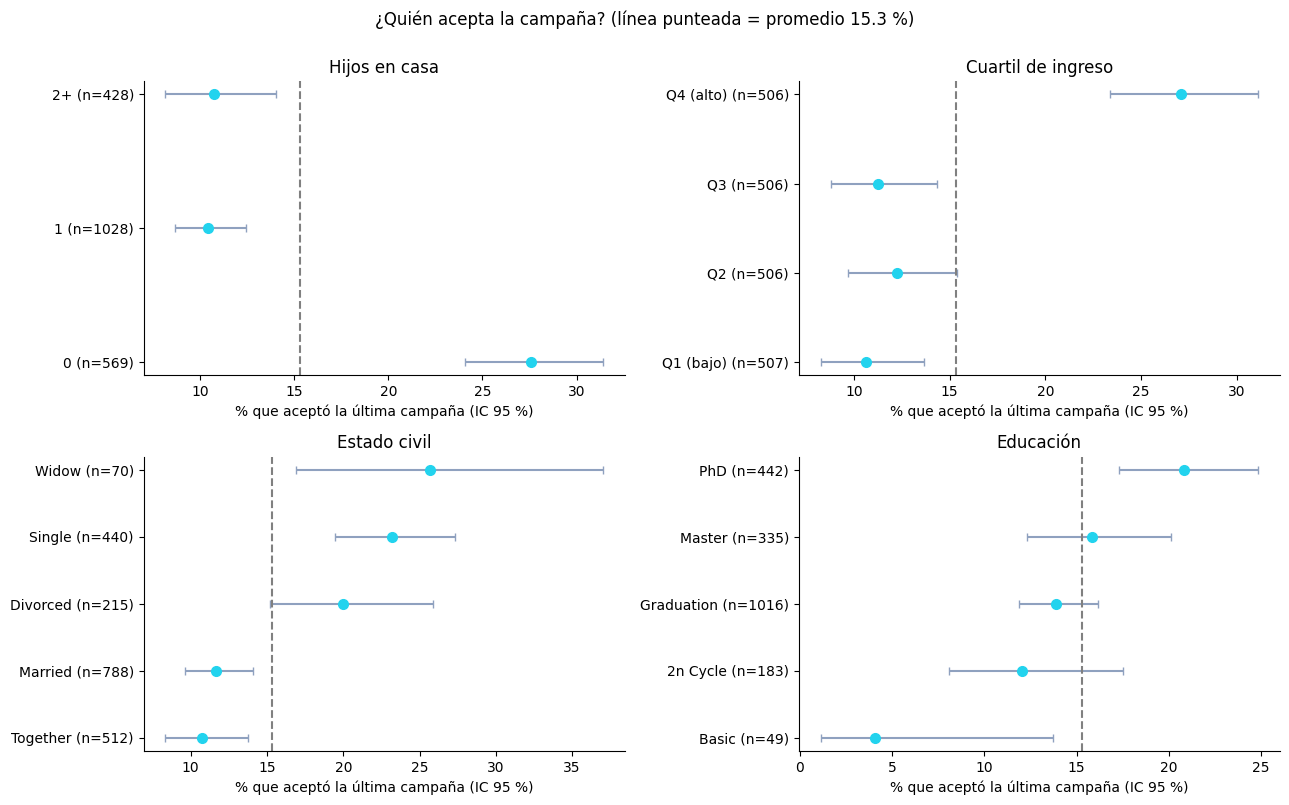

Estilo claro restaurado


In [20]:
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

tasa_global = d["Response"].mean() * 100
paneles = [("Hijos_grupo", "Hijos en casa", False), ("Cuartil_ingreso", "Cuartil de ingreso", False),
           ("Marital_Status", "Estado civil", True), ("Education", "Educación", True)]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (v, titulo, ordenar) in zip(axes.ravel(), paneles):
    g = d.groupby(v, observed=True)["Response"].agg(["sum", "count"])
    g["tasa"] = g["sum"] / g["count"] * 100
    bajo, alto = proportion_confint(g["sum"], g["count"], method="wilson")
    g["bajo"], g["alto"] = bajo * 100, alto * 100
    if ordenar:
        g = g.sort_values("tasa")
    etiquetas = [f"{i} (n={n})" for i, n in zip(g.index, g["count"])]
    y = np.arange(len(g))
    ax.errorbar(g["tasa"], y, xerr=[g["tasa"] - g["bajo"], g["alto"] - g["tasa"]],
                fmt="o", color="#22D3EE", ecolor="#8FA1BF", capsize=3, markersize=7)
    ax.axvline(tasa_global, ls="--", color="gray")
    ax.set_yticks(y)
    ax.set_yticklabels(etiquetas)
    ax.set_title(titulo)
    ax.set_xlabel("% que aceptó la última campaña (IC 95 %)")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"¿Quién acepta la campaña? (línea punteada = promedio {tasa_global:.1f} %)", y=1.0)
plt.tight_layout()
plt.savefig("perfil_aceptacion.png", dpi=150)
plt.show()


In [ ]:
import statsmodels.formula.api as smf

d["Pareja"] = np.where(d["Marital_Status"].isin(["Married", "Together"]), "Con pareja", "Sin pareja")
d["Income_10k"] = d["Income"] / 10000      # ingreso en unidades de 10.000
d["Edad_10"] = d["Edad"] / 10              # edad en décadas
d["Recency_10"] = d["Recency"] / 10        # días desde la última compra, en decenas

formula = ("Response ~ C(Hijos_grupo, Treatment('0')) + Income_10k "
           "+ C(Pareja, Treatment('Con pareja')) + C(Education, Treatment('Graduation')) "
           "+ Edad_10 + Recency_10")
m = smf.logit(formula, data=d).fit(disp=0)

ic = m.conf_int()
tabla = pd.DataFrame({"odds_ratio": np.exp(m.params), "IC_bajo": np.exp(ic[0]),
                      "IC_alto": np.exp(ic[1]), "p": m.pvalues}).drop("Intercept")
print(tabla.round(3).to_string())
print()
print("Pseudo R² (McFadden):", round(m.prsquared, 3), "| clientes:", int(m.nobs))


                                                   odds_ratio  IC_bajo  IC_alto      p
C(Hijos_grupo, Treatment('0'))[T.1]                     0.359    0.262    0.491  0.000
C(Hijos_grupo, Treatment('0'))[T.2+]                    0.389    0.258    0.585  0.000
C(Pareja, Treatment('Con pareja'))[T.Sin pareja]        2.422    1.862    3.150  0.000
C(Education, Treatment('Graduation'))[T.2n Cycle]       0.763    0.457    1.274  0.301
C(Education, Treatment('Graduation'))[T.Basic]          0.354    0.082    1.528  0.164
C(Education, Treatment('Graduation'))[T.Master]         1.194    0.826    1.727  0.346
C(Education, Treatment('Graduation'))[T.PhD]            1.751    1.275    2.404  0.001
Income_10k                                              1.117    1.045    1.194  0.001
Edad_10                                                 0.883    0.791    0.986  0.027
Recency_10                                              0.797    0.760    0.837  0.000

Pseudo R² (McFadden): 0.144 | clientes: 20

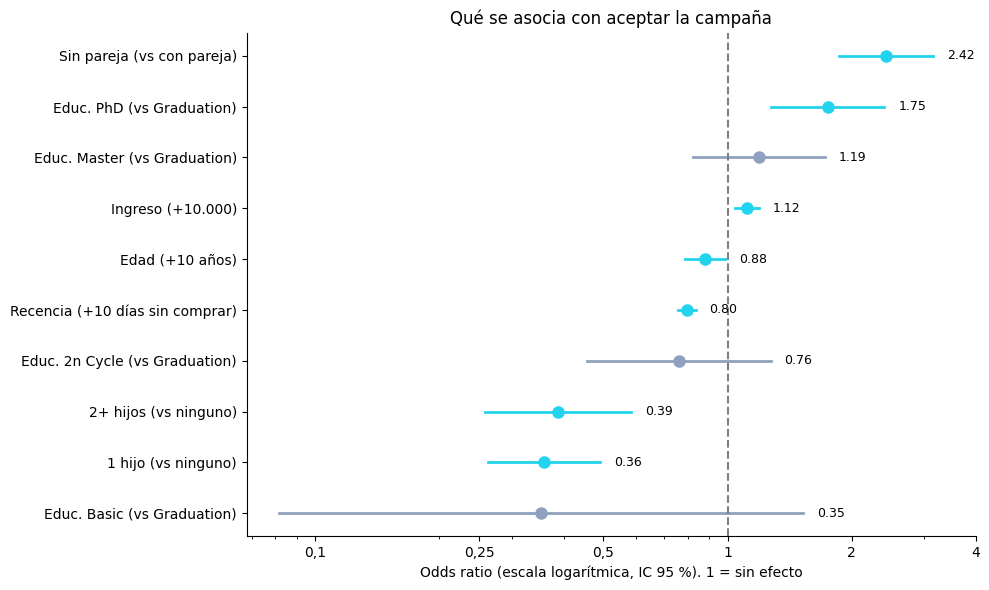

Estilo claro restaurado


In [21]:
nombres = {
    "C(Hijos_grupo, Treatment('0'))[T.1]": "1 hijo (vs ninguno)",
    "C(Hijos_grupo, Treatment('0'))[T.2+]": "2+ hijos (vs ninguno)",
    "C(Pareja, Treatment('Con pareja'))[T.Sin pareja]": "Sin pareja (vs con pareja)",
    "C(Education, Treatment('Graduation'))[T.2n Cycle]": "Educ. 2n Cycle (vs Graduation)",
    "C(Education, Treatment('Graduation'))[T.Basic]": "Educ. Basic (vs Graduation)",
    "C(Education, Treatment('Graduation'))[T.Master]": "Educ. Master (vs Graduation)",
    "C(Education, Treatment('Graduation'))[T.PhD]": "Educ. PhD (vs Graduation)",
    "Income_10k": "Ingreso (+10.000)",
    "Edad_10": "Edad (+10 años)",
    "Recency_10": "Recencia (+10 días sin comprar)",
}
t = tabla.rename(index=nombres).sort_values("odds_ratio")
claro = (t["IC_bajo"] > 1) | (t["IC_alto"] < 1)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(t))
for yi, (_, r), c in zip(y, t.iterrows(), claro):
    col = "#22D3EE" if c else "#8FA1BF"
    ax.plot([r["IC_bajo"], r["IC_alto"]], [yi, yi], color=col, linewidth=2)
    ax.plot(r["odds_ratio"], yi, "o", color=col, markersize=8)
    ax.text(r["IC_alto"] * 1.08, yi, f"{r['odds_ratio']:.2f}", va="center", fontsize=9)

ax.axvline(1, ls="--", color="gray")
ax.set_xscale("log")
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4])
ax.set_xticklabels(["0,1", "0,25", "0,5", "1", "2", "4"])
ax.set_yticks(y)
ax.set_yticklabels(t.index)
ax.set_xlabel("Odds ratio (escala logarítmica, IC 95 %). 1 = sin efecto")
ax.set_title("Qué se asocia con aceptar la campaña")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("odds_ratios_campana.png", dpi=150)
plt.show()
import matplotlib.pyplot as plt


AUC con validación cruzada: 0.751
Tasa base de aceptación: 15.3 %
Contactando al 10 % con mayor probabilidad: llegamos al 30 % de quienes aceptan (x3.0 frente a elegir al azar)
Contactando al 20 % con mayor probabilidad: llegamos al 48 % de quienes aceptan (x2.4 frente a elegir al azar)
Contactando al 30 % con mayor probabilidad: llegamos al 62 % de quienes aceptan (x2.1 frente a elegir al azar)
Contactando al 50 % con mayor probabilidad: llegamos al 79 % de quienes aceptan (x1.6 frente a elegir al azar)


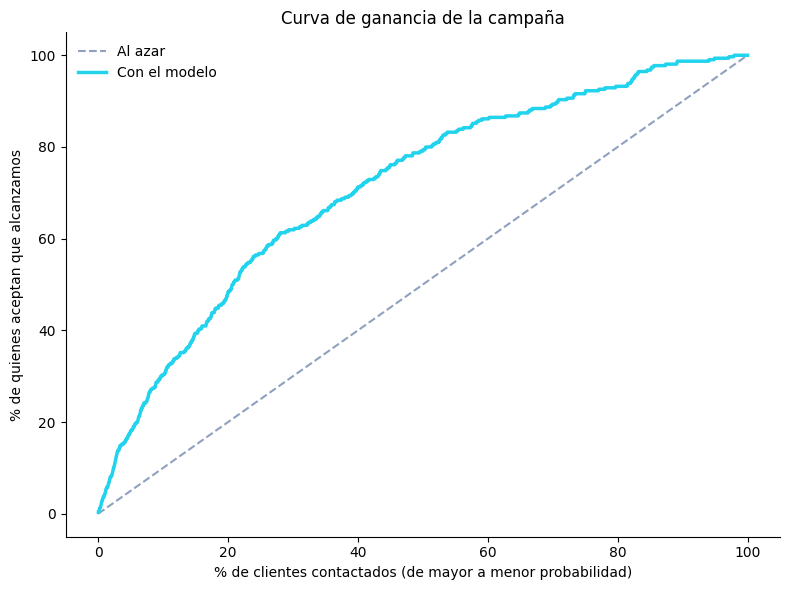

Estilo claro restaurado


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score

num = ["Income", "Edad", "Recency"]
cat = ["Hijos_grupo", "Pareja", "Education"]

pre = ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(drop="first"), cat)])
modelo = make_pipeline(pre, LogisticRegression(max_iter=1000))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p = cross_val_predict(modelo, d[num + cat], d["Response"], cv=cv, method="predict_proba")[:, 1]
print("AUC con validación cruzada:", round(roc_auc_score(d["Response"], p), 3))

# Curva de ganancia: ordenamos a los clientes del más al menos probable
orden = pd.DataFrame({"p": p, "acepto": d["Response"].values}).sort_values("p", ascending=False).reset_index(drop=True)
n = len(orden)
total_acepta = orden["acepto"].sum()
ganancia = orden["acepto"].cumsum() / total_acepta * 100
pct_contactado = (np.arange(1, n + 1) / n) * 100

print(f"Tasa base de aceptación: {orden['acepto'].mean() * 100:.1f} %")
for q in [10, 20, 30, 50]:
    k = int(n * q / 100)
    cap = orden["acepto"][:k].sum() / total_acepta * 100
    print(f"Contactando al {q} % con mayor probabilidad: llegamos al {cap:.0f} % de quienes aceptan (x{cap / q:.1f} frente a elegir al azar)")

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 100], [0, 100], "--", color="#8FA1BF", label="Al azar")
ax.plot(pct_contactado, ganancia, color="#22D3EE", linewidth=2.5, label="Con el modelo")
ax.set_xlabel("% de clientes contactados (de mayor a menor probabilidad)")
ax.set_ylabel("% de quienes aceptan que alcanzamos")
ax.set_title("Curva de ganancia de la campaña")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("curva_ganancia.png", dpi=150)
plt.show()
import matplotlib.pyplot as plt


In [ ]:
# Misma limpieza, pero SIN quitar duplicados
d2 = df.copy()
d2["Marital_Status"] = d2["Marital_Status"].replace({"Alone": "Single"})
d2 = d2[~d2["Marital_Status"].isin(["Absurd", "YOLO"])]
d2 = d2[(d2["Year_Birth"] >= 1920) & ~(d2["Income"] > 200000)].dropna(subset=["Income"])

d2["Edad"] = anio_ref - d2["Year_Birth"]
d2["Hijos_grupo"] = (d2["Kidhome"] + d2["Teenhome"]).clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
d2["Pareja"] = np.where(d2["Marital_Status"].isin(["Married", "Together"]), "Con pareja", "Sin pareja")
d2["Income_10k"] = d2["Income"] / 10000
d2["Edad_10"] = d2["Edad"] / 10
d2["Recency_10"] = d2["Recency"] / 10

m2 = smf.logit(formula, data=d2).fit(disp=0)
ic2 = m2.conf_int()
comparacion = pd.DataFrame({
    "OR_sin_duplicados": np.exp(m.params),
    "OR_con_duplicados": np.exp(m2.params),
    "IC_bajo_con": np.exp(ic2[0]),
    "IC_alto_con": np.exp(ic2[1]),
}).drop("Intercept")
comparacion.index = [nombres[i] for i in comparacion.index]
print("Clientes sin quitar duplicados:", len(d2), "| quitando duplicados:", len(d))
print(comparacion.round(2).to_string())

Clientes sin quitar duplicados: 2208 | quitando duplicados: 2025
                                 OR_sin_duplicados  OR_con_duplicados  IC_bajo_con  IC_alto_con
1 hijo (vs ninguno)                           0.36               0.38         0.28         0.51
2+ hijos (vs ninguno)                         0.39               0.40         0.27         0.59
Sin pareja (vs con pareja)                    2.42               2.41         1.87         3.11
Educ. 2n Cycle (vs Graduation)                0.76               0.74         0.44         1.22
Educ. Basic (vs Graduation)                   0.35               0.35         0.08         1.51
Educ. Master (vs Graduation)                  1.19               1.17         0.82         1.67
Educ. PhD (vs Graduation)                     1.75               1.76         1.30         2.38
Ingreso (+10.000)                             1.12               1.13         1.06         1.20
Edad (+10 años)                               0.88               0.90  

In [ ]:
d.to_csv("campanas_limpio.csv", index=False)
tabla.round(3).reset_index().rename(columns={"index": "variable"}).to_csv("campanas_odds_ratios.csv", index=False)
print("Guardados: campanas_limpio.csv, campanas_odds_ratios.csv")

Guardados: campanas_limpio.csv, campanas_odds_ratios.csv


In [ ]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "#0B1220", "axes.facecolor": "#111A2E", "savefig.facecolor": "#0B1220",
    "axes.edgecolor": "#1E2A44", "axes.labelcolor": "#C9D4E8", "text.color": "#E6ECF8",
    "xtick.color": "#9FB0CC", "ytick.color": "#9FB0CC",
    "axes.grid": True, "grid.color": "#1E2A44", "grid.linestyle": ":",
    "axes.titlesize": 14, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False, "legend.labelcolor": "#E6ECF8",
    "axes.spines.top": False, "axes.spines.right": False,
})
print("Estilo oscuro activado")

Estilo oscuro activado
